# Rémy trees

[← All examples](../paper_examples.ipynb) · [Python analysis](../../tutorials/remy_analysis.py) · [Model inputs](../../src/mfobs/models/remy/inputs.py)

Starting from the left-spine count P3, six insertion rules discover P2, P1 and E and a closed expectation ODE. All rules share the rate κ.


<nav class="example-sections" aria-label="Example sections" style="display:flex;align-items:stretch;gap:5px;flex-wrap:wrap;margin:16px auto;padding-top:8px;padding-bottom:8px;border-bottom:1px solid #cddce1"><span data-topic="rules" style="background:#e7f3e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="https://stochmech.algochem.techfak.de/experiments/remy-trees/index.html#rules" target="_blank" rel="noopener noreferrer" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">1 · Rules &amp; state space ↗ Web</a></span><span data-topic="inputs" style="background:#fbe9e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="https://stochmech.algochem.techfak.de/experiments/remy-trees/index.html#inputs" target="_blank" rel="noopener noreferrer" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">2 · Inputs &amp; semantics ↗ Web</a></span><span data-topic="observables" style="background:#e8f0fb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=section-nav-89b5b8ab" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">3 · Observable discovery</a></span><span data-topic="ode" style="background:#f0eafb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap">4 · <a href="#cell-id=section-nav-89b5b8ab" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">ODE</a> &amp; <a href="https://stochmech.algochem.techfak.de/experiments/remy-trees/index.html#events" target="_blank" rel="noopener noreferrer" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">pJC ↗ Web</a></span><span data-topic="initial" style="background:#e3f3f0;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=8c6523a5" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">5 · Initial states</a></span><span data-topic="dynamics" style="background:#fff0de;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=section-nav-8b509420" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">6 · Dynamics</a></span></nav>

In [1]:
from pathlib import Path
import sys
PACKAGE = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/mfobs').is_dir()))
NOTEBOOKS = PACKAGE / 'notebooks'
sys.path[:0] = [str(NOTEBOOKS), str(PACKAGE / 'src'), str(PACKAGE)]
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import visual_view as visual
from IPython.display import display, Math
import sympy as sp

In [2]:
from mfobs import analyze
from mfobs.applications import RemyTrees
backend = RemyTrees(order=3)
defaults = backend.specification()
Omega = defaults.omega
rules = defaults.rules
observables = defaults.observables
from mfobs import ModelInputs
inputs = ModelInputs(Omega, rules, observables)
result = analyze(inputs, linear_limit=16, record_patterns=True, backend=backend).record()

<p><strong style="background:#e8f0fb;padding:4px 8px;border-radius:4px">3 · Observable discovery</strong> · <strong style="background:#f0eafb;padding:4px 8px;border-radius:4px">4 · ODE</strong></p>

In [3]:
print("Discovered basis:", result["linear"]["basis"])
print("Linear closure:", result["linear"]["status"])
for step in result["linear"]["steps"]:
    rhs = sp.Add(*(sp.Rational(c) * sp.Symbol(name) for name, c in step["coordinates"].items()))
    display(Math(r"\frac{d}{dt}\mathbb{E}[" + step["source"] + r"] = \kappa\,\mathbb{E}[" + sp.latex(rhs) + "]"))

Discovered basis: ['P3', 'P2', 'P1', 'E']
Linear closure: CLOSED


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 5 · Initial states

Start from one leaf and its exterior stem: **E=1, P1=P2=P3=0**. Integrate the generated linear expectation ODE.


In [4]:
KAPPA = 0.25
T = 3.

<p><strong style="background:#fff0de;padding:4px 8px;border-radius:4px">6 · Dynamics</strong></p>

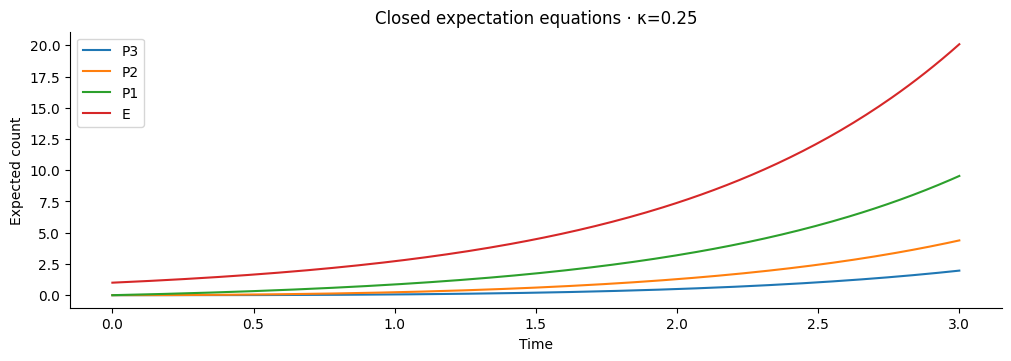

Run All in JupyterLab to activate the sliders.

In [5]:
visual.close_controls(globals().get("controls"))
curves = visual.show_curve(visual.remy_curve(result, rate=KAPPA, end=T))
controls = visual.remy_sliders(result, curves, rate=KAPPA, end=T)

[← All examples](../paper_examples.ipynb)